In [2]:
import pandas as pd

ballenas = pd.read_csv("Ballena_Jorobada_Pacifico_Norte_2025-2026.csv")
ballenas.head()

,fecha_avistamiento,fecha_hora_original,anio,mes,especie,latitud,longitud,incertidumbre_m,region_marina,localidad_reportada,id_individuo,id_avistamiento,enlace_avistamiento,roni_c_noaa,doi_fuente
0,2025-01-01,2025-01-01,2025,1,Megaptera novaeangliae,20.895028,-156.703981,1.11,North Pacific Ocean,"Hawaii, United States",6306.0,518545,https://happywhale.com/individual/6306;enc=518545,-1.1,10.82144/4991ec34
1,2025-01-01,2025-01-01,2025,1,Megaptera novaeangliae,36.703153,-121.872323,11131.95,North Pacific Ocean,"California, United States",24097.0,518940,https://happywhale.com/individual/24097;enc=51...,-1.1,10.82144/4991ec34
2,2025-01-01,2025-01-01,2025,1,Megaptera novaeangliae,20.870000,-156.700000,111319.49,North Pacific Ocean,"Hawaii, United States",133461.0,520044,https://happywhale.com/individual/133461;enc=5...,-1.1,10.82144/4991ec34
3,2025-01-01,2025-01-01,2025,1,Megaptera novaeangliae,20.870000,-156.700000,111319.49,North Pacific Ocean,"Hawaii, United States",82566.0,520045,https://happywhale.com/individual/82566;enc=52...,-1.1,10.82144/4991ec34
4,2025-01-01,2025-01-01,2025,1,Megaptera novaeangliae,20.870000,-156.700000,111319.49,North Pacific Ocean,"Hawaii, United States",58592.0,520046,https://happywhale.com/individual/58592;enc=52...,-1.1,10.82144/4991ec34


## Descripción del conjunto de datos

La base contiene 51.287 registros de avistamientos de ballena jorobada
(*Megaptera novaeangliae*) en el Pacífico Norte, comprende las fechas entre el 1 de enero de
2025 y el 29 de octubre de 2026. Cada fila representa un avistamiento.
La tabla incluye la fecha, la latitud, la longitud y, cuando está disponible,
el identificador de la ballena. Un mismo individuo puede aparecer en
varios registros.

Fuente de los avistamientos: [Happywhale y OBIS-SEAMAP](https://doi.org/10.82144/4991ec34).

In [3]:
ballenas.shape

(51287, 15)

In [4]:
ballenas.columns

Index(['fecha_avistamiento', 'fecha_hora_original', 'anio', 'mes', 'especie',
       'latitud', 'longitud', 'incertidumbre_m', 'region_marina',
       'localidad_reportada', 'id_individuo', 'id_avistamiento',
       'enlace_avistamiento', 'roni_c_noaa', 'doi_fuente'],
      dtype='str')

In [5]:
ballenas["anio"].value_counts().sort_index()

anio
2025    27231
2026    24056
Name: count, dtype: int64

In [6]:
registros_mes = ballenas.groupby(["mes", "anio"]).size().unstack()

In [7]:
registros_mes

anio,2025,2026
mes,,
1,2622.0,3922.0
2,3001.0,3859.0
3,2522.0,2786.0
4,1418.0,731.0
5,1244.0,1247.0
6,2275.0,2187.0
7,3396.0,2752.0
8,3450.0,2957.0
9,2483.0,2670.0


<Axes: xlabel='mes'>

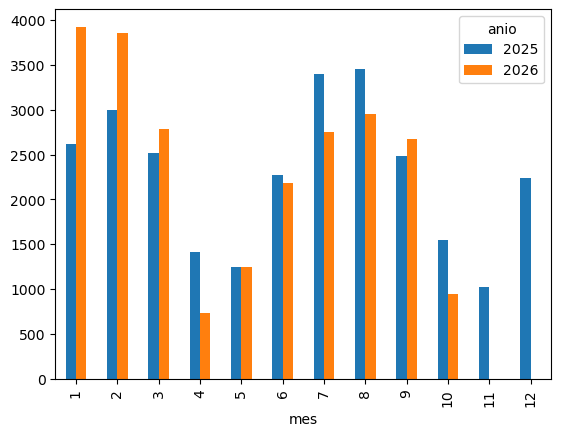

In [8]:
registros_mes.plot(kind="bar")

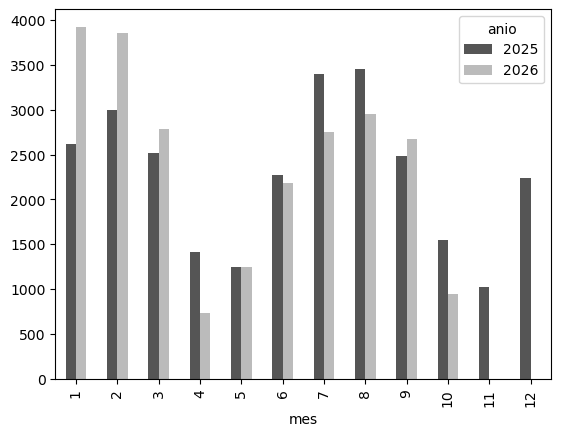

In [11]:
ax = registros_mes.plot(kind="bar", color=["#555555", "#BBBBBB"])

In [12]:
ax.legend(title="Año")

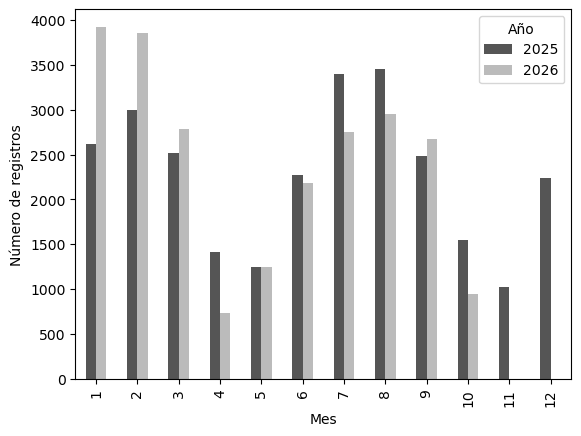

In [15]:
import matplotlib.pyplot as plt
ax = registros_mes.plot(kind="bar", color=["#555555", "#BBBBBB"])
ax.legend(title="Año")
ax.set_xlabel("Mes")
ax.set_ylabel("Número de registros")
plt.show()

In [16]:
def filtrar_por_anio(datos, anio):
    """filtra la tabla para seleccionar un año."""
    return datos[datos["anio"] == anio]

In [17]:
ballenas_2025 = filtrar_por_anio(ballenas, 2025)

In [18]:
ballenas_2025.shape

(27231, 15)